In [1]:
from pathlib import Path
import joblib
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

PROJECT_ROOT = Path.cwd()
MODEL_PATH = PROJECT_ROOT / "models" / "tuned_xgboost.pkl"
OUTPUT_DIR = PROJECT_ROOT / "reports" / "tree_visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model path:", MODEL_PATH)
print("Exists:", MODEL_PATH.exists())
print("XGBoost version:", xgb.__version__)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model not found: {MODEL_PATH}. Update MODEL_PATH to your saved tuned XGBoost model."
    )

model = joblib.load(MODEL_PATH)
print("Loaded estimator:", type(model).__name__)

Model path: c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\tuned_xgboost.pkl
Exists: True
XGBoost version: 3.0.5
Loaded estimator: XGBClassifier


In [10]:
# Resolve the Booster from a saved XGBoost estimator or Booster.
if hasattr(model, "get_booster"):
    booster = model.get_booster()
elif isinstance(model, xgb.Booster):
    booster = model
else:
    raise TypeError(
        "The loaded object is not a recognized XGBoost estimator/Booster. "
        f"Loaded type: {type(model).__name__}"
    )

dump = booster.get_dump(dump_format="text")
print("Number of boosted trees:", len(dump))
print("Booster feature names:", booster.feature_names)
print("Booster input feature count:", booster.num_features())

Number of boosted trees: 100
Booster feature names: None
Booster input feature count: 51


In [11]:
# Graphviz-free tree renderer using Matplotlib.
import re

def _feature_label(split_text, feature_names=None):
    # XGBoost split strings typically look like f12<0.5 or f12>=0.5.
    match = re.match(r"^f(\d+)(.*)$", split_text)
    if match and feature_names is not None:
        index = int(match.group(1))
        if index < len(feature_names):
            return f"{feature_names[index]}{match.group(2)}"
    return split_text

def _parse_xgb_tree(tree_text):
    nodes = {}
    for raw_line in tree_text.splitlines():
        line = raw_line.strip()
        split_match = re.match(
            r"(\d+):\[(.+?)\]\s+yes=(\d+),no=(\d+),missing=(\d+)(?:,.*)?$", line
        )
        if split_match:
            node_id, split, yes, no, missing = split_match.groups()
            nodes[int(node_id)] = {
                "kind": "split", "split": split, "yes": int(yes),
                "no": int(no), "missing": int(missing), "raw": line
            }
            continue
        leaf_match = re.match(r"(\d+):leaf=(.+?)(?:,.*)?$", line)
        if leaf_match:
            node_id, value = leaf_match.groups()
            nodes[int(node_id)] = {"kind": "leaf", "value": value, "raw": line}
    if not nodes:
        raise ValueError("Could not parse this XGBoost tree dump. Check the installed XGBoost version.")
    return nodes

def _render_tree_matplotlib(tree_text, max_depth=3, figsize=(22, 10),
                            title="XGBoost decision tree", feature_names=None,
                            save_path=None, dpi=220):
    nodes = _parse_xgb_tree(tree_text)
    positions, display_nodes, visible_edges = {}, {}, []
    leaf_counter = [0]

    def layout(node_id, depth):
        node = nodes.get(node_id)
        if node is None:
            x = leaf_counter[0]; leaf_counter[0] += 1
            positions[node_id] = (x, -depth)
            display_nodes[node_id] = {"label": f"Node {node_id}\nmissing from dump", "kind": "leaf"}
            return x

        if node["kind"] == "leaf":
            x = leaf_counter[0]; leaf_counter[0] += 1
            positions[node_id] = (x, -depth)
            display_nodes[node_id] = {"label": f"Leaf {node_id}\nvalue = {node['value']}", "kind": "leaf"}
            return x

        readable_split = _feature_label(node["split"], feature_names)
        if depth >= max_depth:
            x = leaf_counter[0]; leaf_counter[0] += 1
            positions[node_id] = (x, -depth)
            display_nodes[node_id] = {
                "label": f"{readable_split}\n… depth limit", "kind": "cut"
            }
            return x

        left_x = layout(node["yes"], depth + 1)
        right_x = layout(node["no"], depth + 1)
        x = (left_x + right_x) / 2
        positions[node_id] = (x, -depth)
        display_nodes[node_id] = {"label": readable_split, "kind": "split"}
        visible_edges.extend([(node_id, node["yes"], "yes"), (node_id, node["no"], "no")])
        return x

    layout(0, 0)
    fig, ax = plt.subplots(figsize=figsize)
    for parent, child, branch in visible_edges:
        x1, y1 = positions[parent]; x2, y2 = positions[child]
        ax.plot([x1, x2], [y1 - 0.08, y2 + 0.08], linewidth=1.2, color="#65758B")
        ax.text((x1+x2)/2, (y1+y2)/2, branch, ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
    for node_id, (x, y) in positions.items():
        info = display_nodes[node_id]
        face = "#E8F1FB" if info["kind"] == "split" else (
            "#FFF0D9" if info["kind"] == "cut" else "#E7F5E8"
        )
        ax.text(x, y, info["label"], ha="center", va="center", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=face,
                          edgecolor="#536273", linewidth=0.8))
    ax.set_title(title, fontsize=14, pad=18)
    ax.axis("off")
    ax.margins(x=0.08, y=0.15)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print("Saved:", save_path)
    return fig, ax

print("Matplotlib tree renderer is ready.")


Matplotlib tree renderer is ready.


In [28]:
# Select the tree and resolve readable feature names.
TREE_INDEX = 0
MAX_DEPTH = 3
FIGSIZE = (22, 10)

if not 0 <= TREE_INDEX < len(dump):
    raise IndexError(f"TREE_INDEX must be between 0 and {len(dump)-1}")

# Exact transformed feature names supplied for this model's training pipeline.
# These are used only when the feature count matches the saved Booster.
provided_feature_names = ['num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__SeniorCitizen_No', 'cat__SeniorCitizen_Yes', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes', 'cat__PhoneService_No', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_No internet service', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_No', 'cat__DeviceProtection_No internet service', 'cat__DeviceProtection_Yes', 'cat__TechSupport_No', 'cat__TechSupport_No internet service', 'cat__TechSupport_Yes', 'cat__StreamingTV_No', 'cat__StreamingTV_No internet service', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_No', 'cat__StreamingMovies_No internet service', 'cat__StreamingMovies_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaperlessBilling_No', 'cat__PaperlessBilling_Yes', 'cat__PaymentMethod_Bank transfer (automatic)', 'cat__PaymentMethod_Credit card (automatic)', 'cat__PaymentMethod_Electronic check', 'cat__PaymentMethod_Mailed check', 'cat__tenure_group_1 - 12', 'cat__tenure_group_13 - 24', 'cat__tenure_group_25 - 36', 'cat__tenure_group_37 - 48', 'cat__tenure_group_49 - 60']

tree_feature_names = None
booster_feature_count = booster.num_features()

# First preference: names from the matching fitted preprocessor, if present.
PREPROCESSOR_CANDIDATES = [
    PROJECT_ROOT / "artifacts" / "preprocessor.pkl",
    PROJECT_ROOT / "models" / "preprocessor.pkl",
]
preprocessor_path = next((p for p in PREPROCESSOR_CANDIDATES if p.exists()), None)

if preprocessor_path is not None:
    try:
        preprocessor = joblib.load(preprocessor_path)
        names_from_preprocessor = list(preprocessor.get_feature_names_out())
        print("Preprocessor:", preprocessor_path)
        print("Preprocessor feature count:", len(names_from_preprocessor))
        if len(names_from_preprocessor) == booster_feature_count:
            tree_feature_names = names_from_preprocessor
            print("Using transformed names from the fitted preprocessor.")
        else:
            print("Preprocessor feature count does not match the Booster; trying the supplied name list.")
    except Exception as exc:
        print("Could not read feature names from preprocessor:", repr(exc))

# Fallback: the names supplied in the conversation, mapped strictly by column order.
if tree_feature_names is None:
    if len(provided_feature_names) == booster_feature_count:
        tree_feature_names = provided_feature_names
        print("Using the supplied transformed feature names by column order.")
    else:
        print(
            f"WARNING: supplied name list has {len(provided_feature_names)} names, "
            f"but Booster expects {booster_feature_count}. Labels will remain generic "
            "to avoid an incorrect mapping."
        )

if tree_feature_names is not None:
    print("Feature-name mapping enabled. Examples:")
    print({f"f{i}": name for i, name in enumerate(tree_feature_names[:8])})
else:
    print("Feature-name mapping is disabled.")


Preprocessor: c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\preprocessor.pkl
Preprocessor feature count: 51
Using transformed names from the fitted preprocessor.
Feature-name mapping enabled. Examples:
{'f0': 'num__MonthlyCharges', 'f1': 'num__TotalCharges', 'f2': 'cat__gender_Female', 'f3': 'cat__gender_Male', 'f4': 'cat__SeniorCitizen_No', 'f5': 'cat__SeniorCitizen_Yes', 'f6': 'cat__Partner_No', 'f7': 'cat__Partner_Yes'}


Saved: c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\reports\tree_visualizations\xgboost_tree_0_depth_3.png


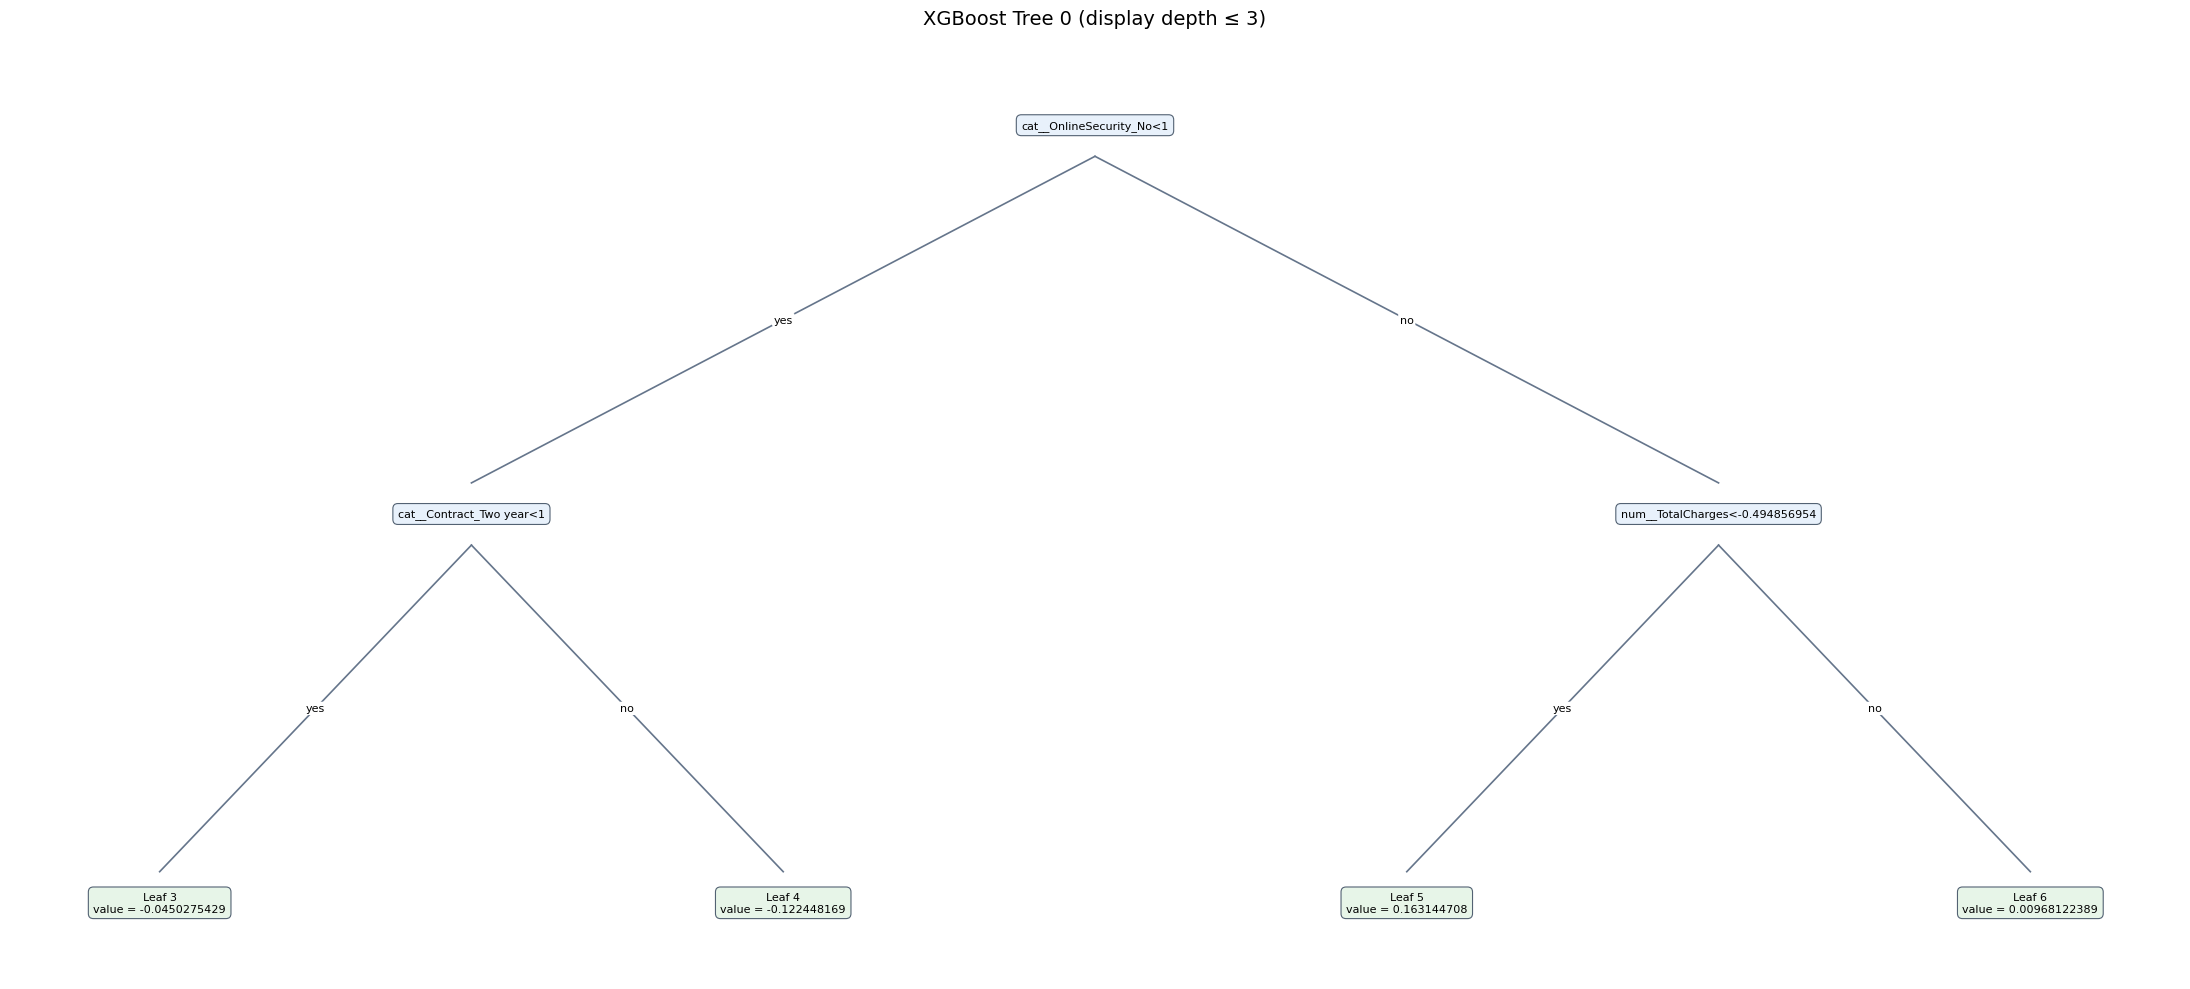

In [29]:
tree_png = OUTPUT_DIR / f"xgboost_tree_{TREE_INDEX}_depth_{MAX_DEPTH}.png"
fig, ax = _render_tree_matplotlib(
    dump[TREE_INDEX],
    max_depth=MAX_DEPTH,
    figsize=FIGSIZE,
    title=f"XGBoost Tree {TREE_INDEX} (display depth ≤ {MAX_DEPTH})",
    feature_names=tree_feature_names,
    save_path=tree_png,
    dpi=220,
)
plt.show()


In [21]:
tree_text = dump[TREE_INDEX]
if tree_feature_names is not None:
    def _replace_feature_id(match):
        idx = int(match.group(1))
        return tree_feature_names[idx] if idx < len(tree_feature_names) else match.group(0)
    readable_tree_text = re.sub(r"\bf(\d+)\b", _replace_feature_id, tree_text)
else:
    readable_tree_text = tree_text

print(readable_tree_text[:12000])
if len(readable_tree_text) > 12000:
    print("\n... output truncated; inspect `readable_tree_text` for the complete tree.")


0:[cat__OnlineSecurity_No<1] yes=1,no=2,missing=2
	1:[cat__Contract_Two year<1] yes=3,no=4,missing=4
		3:leaf=-0.0450275429
		4:leaf=-0.122448169
	2:[num__TotalCharges<-0.494856954] yes=5,no=6,missing=6
		5:leaf=0.163144708
		6:leaf=0.00968122389



In [16]:
# Verify the feature-name mapping used in the graph.
print("Booster input feature count:", booster.num_features())
print("Mapped feature-name count:", len(tree_feature_names) if tree_feature_names is not None else 0)
if tree_feature_names is not None:
    print("Names align by feature count.")
    print("First 50 transformed names:")
    print(tree_feature_names[:50])
    print("Example mappings:", {f"f{i}": tree_feature_names[i] for i in range(min(10, len(tree_feature_names)))})
else:
    print("No safe mapping available. Check that the supplied names/preprocessor match the exact model input order.")


Booster input feature count: 51
Mapped feature-name count: 51
Names align by feature count.
First 50 transformed names:
['num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__SeniorCitizen_No', 'cat__SeniorCitizen_Yes', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes', 'cat__PhoneService_No', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_No internet service', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_No', 'cat__DeviceProtection_No internet service', 'cat__DeviceProtection_Yes', 'cat__TechSupport_No', 'cat__TechSupport_No internet service', 'cat__TechSupport_Yes', 'cat__StreamingTV_No', 'cat__StreamingTV_No internet 